In [ ]:
## Step 1: Load the Raw M5 Datasets

#This cell imports the required libraries and loads the three M5 Forecasting
#Accuracy files (calendar, sell prices, and sales history) directly from the
#local project folder. The shape of each dataset is printed to confirm the
#files loaded correctly before any processing begins.

In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)

# Set the data folder path
data_path = r"C:\Users\waughma\OneDrive - Viega GmbH & Co. KG\Documents\CSU-Global\MIS581 - Business Analytics Capstone"

# Load the three M5 files
calendar = pd.read_csv(data_path + r"\calendar.csv")
sell_prices = pd.read_csv(data_path + r"\sell_prices.csv")
sales = pd.read_csv(data_path + r"\sales_train_validation.csv")

print("Calendar shape:", calendar.shape)
print("Sell prices shape:", sell_prices.shape)
print("Sales (wide format) shape:", sales.shape)

Calendar shape: (1969, 14)
Sell prices shape: (6841121, 4)
Sales (wide format) shape: (30490, 1919)


In [ ]:
## Step 2: Inspect the Structure of Each Dataset

#Before merging the three files, it is important to understand what each one
#contains. This cell previews the column names and data types for the
#calendar, sell prices, and sales datasets, and displays the first few rows
#of each so the structure is clear before any data preparation begins.

In [3]:
# Calendar structure
print("=== CALENDAR ===")
print(calendar.dtypes)
calendar.head()

=== CALENDAR ===
date            object
wm_yr_wk         int64
weekday         object
wday             int64
month            int64
year             int64
d               object
event_name_1    object
event_type_1    object
event_name_2    object
event_type_2    object
snap_CA          int64
snap_TX          int64
snap_WI          int64
dtype: object


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [4]:
# Sell prices structure
print("=== SELL PRICES ===")
print(sell_prices.dtypes)
sell_prices.head()

=== SELL PRICES ===
store_id       object
item_id        object
wm_yr_wk        int64
sell_price    float64
dtype: object


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [5]:
# Sales structure (first few ID columns and first few day columns only, since it's wide)
print("=== SALES (ID columns + first 5 day columns) ===")
id_cols = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
day_cols_preview = [c for c in sales.columns if c.startswith('d_')][:5]
print(sales[id_cols + day_cols_preview].dtypes)
sales[id_cols + day_cols_preview].head()

=== SALES (ID columns + first 5 day columns) ===
id          object
item_id     object
dept_id     object
cat_id      object
store_id    object
state_id    object
d_1          int64
d_2          int64
d_3          int64
d_4          int64
d_5          int64
dtype: object


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0


In [ ]:
## Step 3: Summary Statistics for Each Dataset

#Before reshaping or merging the data, this cell produces summary statistics
#for each file to confirm data quality and understand its basic
#characteristics. This includes checking for missing values, reviewing the
#frequency of calendar events and SNAP days, summarizing the price data, and
#examining the overall distribution of daily unit sales (including the
#proportion of zero-sales observations, which is a known characteristic of
#this dataset).

In [6]:
# --- Missing values in each dataset ---
print("=== MISSING VALUES ===")
print("Calendar:\n", calendar.isnull().sum())
print("\nSell prices:\n", sell_prices.isnull().sum())
print("\nSales (ID columns only):\n", sales[id_cols].isnull().sum())

=== MISSING VALUES ===
Calendar:
 date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

Sell prices:
 store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64

Sales (ID columns only):
 id          0
item_id     0
dept_id     0
cat_id      0
store_id    0
state_id    0
dtype: int64


In [7]:
# --- Calendar: event and SNAP frequency ---
print("=== CALENDAR EVENT COUNTS ===")
print(calendar['event_type_1'].value_counts(dropna=True))
print("\n=== SNAP DAYS PER STATE (out of", len(calendar), "days) ===")
print("snap_CA:", calendar['snap_CA'].sum())
print("snap_TX:", calendar['snap_TX'].sum())
print("snap_WI:", calendar['snap_WI'].sum())

=== CALENDAR EVENT COUNTS ===
event_type_1
Religious    55
National     52
Cultural     37
Sporting     18
Name: count, dtype: int64

=== SNAP DAYS PER STATE (out of 1969 days) ===
snap_CA: 650
snap_TX: 650
snap_WI: 650


In [8]:
# --- Sell prices: descriptive statistics ---
print("=== SELL PRICES SUMMARY ===")
print(sell_prices['sell_price'].describe())
print("\nUnique items:", sell_prices['item_id'].nunique())
print("Unique stores:", sell_prices['store_id'].nunique())

=== SELL PRICES SUMMARY ===
count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

Unique items: 3049
Unique stores: 10


In [9]:
# --- Sales: overall daily unit sales distribution ---
day_cols = [c for c in sales.columns if c.startswith('d_')]
all_sales_values = sales[day_cols].values.flatten()

print("=== DAILY UNIT SALES SUMMARY (all products, all days) ===")
print("Mean:", np.mean(all_sales_values))
print("Median:", np.median(all_sales_values))
print("Std Dev:", np.std(all_sales_values))
print("Min:", np.min(all_sales_values))
print("Max:", np.max(all_sales_values))
pct_zero = (all_sales_values == 0).mean() * 100
print(f"Percent of observations equal to zero: {pct_zero:.2f}%")

=== DAILY UNIT SALES SUMMARY (all products, all days) ===
Mean: 1.126322153733316
Median: 0.0
Std Dev: 3.8731084132705003
Min: 0
Max: 763
Percent of observations equal to zero: 68.20%


In [10]:
# Step 4: Reshape Sales Data from Wide to Long Format

#The sales data currently has one row per product/store combination, with a
#separate column for each of the 1,913 days (wide format). To merge this
#with the calendar and price data,it needs to be reshaped into long format,
#with one row per product/store/day combination instead. This will produce
#a much larger dataframe, so category data types are used for the ID columns
#to keep memory usage manageable.

In [11]:
# Convert ID columns to category dtype to save memory before reshaping
for col in id_cols:
    sales[col] = sales[col].astype('category')

# Reshape from wide to long format
sales_long = pd.melt(
    sales,
    id_vars=id_cols,
    value_vars=day_cols,
    var_name='d',
    value_name='sales'
)

# Downcast the sales column to save memory
sales_long['sales'] = sales_long['sales'].astype('int32')

print("Sales long format shape:", sales_long.shape)
sales_long.head()

Sales long format shape: (58327370, 8)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [14]:
## Step 5: Merge Calendar Data into the Sales Data

#This cell optimizes the calendar dataset's data types and merges it into
#the long-format sales data using the shared `d` column. This attaches the
#actual date, the week identifier needed for the price merge, calendar
#event information, and SNAP indicators to every sales record.

In [15]:
calendar_opt = calendar.copy()
calendar_opt['d'] = calendar_opt['d'].astype('category')
calendar_opt['wm_yr_wk'] = calendar_opt['wm_yr_wk'].astype('int16')
calendar_opt['wday'] = calendar_opt['wday'].astype('int8')
calendar_opt['month'] = calendar_opt['month'].astype('int8')
calendar_opt['year'] = calendar_opt['year'].astype('int16')
calendar_opt['snap_CA'] = calendar_opt['snap_CA'].astype('int8')
calendar_opt['snap_TX'] = calendar_opt['snap_TX'].astype('int8')
calendar_opt['snap_WI'] = calendar_opt['snap_WI'].astype('int8')

for col in ['weekday', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']:
    calendar_opt[col] = calendar_opt[col].astype('category')

sales_long = sales_long.merge(calendar_opt, on='d', how='left')

print("Sales long shape after calendar merge:", sales_long.shape)
print("Memory usage (MB):", round(sales_long.memory_usage(deep=True).sum() / 1e6, 1))
sales_long.head()

Sales long shape after calendar merge: (58327370, 21)
Memory usage (MB): 8135.8


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0


In [16]:
## Step 6: Merge Sell Price Data into the Sales Data

#This cell optimizes the sell prices dataset's data types and merges it into
#the sales/calendar data using store_id, item_id, and wm_yr_wk (the week
#identifier) as the join keys. Not every item was sold at every store during
#every week, so a left join is used and any resulting missing prices are
#reported, since these represent weeks when a given item was not yet stocked
#or had not yet been introduced at a given store.

In [17]:
sell_prices_opt = sell_prices.copy()
sell_prices_opt['store_id'] = sell_prices_opt['store_id'].astype('category')
sell_prices_opt['item_id'] = sell_prices_opt['item_id'].astype('category')
sell_prices_opt['wm_yr_wk'] = sell_prices_opt['wm_yr_wk'].astype('int16')
sell_prices_opt['sell_price'] = sell_prices_opt['sell_price'].astype('float32')

sales_long = sales_long.merge(
    sell_prices_opt,
    on=['store_id', 'item_id', 'wm_yr_wk'],
    how='left'
)

print("Sales long shape after price merge:", sales_long.shape)
print("Memory usage (MB):", round(sales_long.memory_usage(deep=True).sum() / 1e6, 1))

missing_price_pct = sales_long['sell_price'].isnull().mean() * 100
print(f"Percent of rows with no price (item not yet stocked): {missing_price_pct:.2f}%")

sales_long.head()

Sales long shape after price merge: (58327370, 22)
Memory usage (MB): 8369.1
Percent of rows with no price (item not yet stocked): 21.09%


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN


In [18]:
## Step 7: Remove Rows Where the Item Was Not Yet Stocked

#A missing sell_price indicates a week in which a given item had not yet
#been introduced at a given store, rather than a genuine zero-demand
#observation. Including these rows would misrepresent actual demand
#patterns, since the item was not actually available for purchase during
#that period. This cell removes those rows and confirms the resulting
#dataset size before any further variables are engineered.

In [19]:
rows_before = sales_long.shape[0]

sales_long = sales_long[sales_long['sell_price'].notnull()].copy()

rows_after = sales_long.shape[0]
rows_dropped = rows_before - rows_after

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows dropped:", rows_dropped, f"({rows_dropped / rows_before * 100:.2f}%)")
print("New shape:", sales_long.shape)

# Confirm zero-sales observations are still well represented among available (stocked) items
pct_zero_available = (sales_long['sales'] == 0).mean() * 100
print(f"Percent of remaining (in-stock) observations equal to zero: {pct_zero_available:.2f}%")

Rows before: 58327370
Rows after: 46027957
Rows dropped: 12299413 (21.09%)
New shape: (46027957, 22)
Percent of remaining (in-stock) observations equal to zero: 59.70%


In [21]:
## Step 8: Engineer the Marketing-Related Variables
# Create a binary indicator for whether a calendar event occurred (event_name_1 or event_name_2 present)
sales_long['has_event'] = (
    sales_long['event_name_1'].notnull() | sales_long['event_name_2'].notnull()
).astype('int8')

print("Percent of rows with an event:", round(sales_long['has_event'].mean() * 100, 2))
sales_long['has_event'].value_counts()

Percent of rows with an event: 8.01


has_event
0    42341567
1     3686390
Name: count, dtype: int64

In [22]:
# Sort by item/store/date so price changes can be measured week over week
sales_long = sales_long.sort_values(['store_id', 'item_id', 'date']).reset_index(drop=True)

# Flag whether the price changed from the prior available observation for that item/store
sales_long['price_change'] = (
    sales_long.groupby(['store_id', 'item_id'], observed=True)['sell_price']
    .diff()
    .fillna(0)
    .ne(0)
    .astype('int8')
)

print("Percent of rows with a price change:", round(sales_long['price_change'].mean() * 100, 2))
sales_long['price_change'].value_counts()

Percent of rows with a price change: 0.17


price_change
0    45950754
1       77203
Name: count, dtype: int64

In [24]:
## Step 9: Test RQ1 - relationship between marketing-related variables and demand
import statsmodels.api as sm

# Independent variables: event indicator, price change indicator, and price level
X = sales_long[['has_event', 'price_change', 'sell_price']]
X = sm.add_constant(X)
y = sales_long['sales']

rq1_model = sm.OLS(y, X).fit()
print(rq1_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                 3.579e+05
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        11:38:57   Log-Likelihood:            -1.3203e+08
No. Observations:            46027957   AIC:                         2.641e+08
Df Residuals:                46027953   BIC:                         2.641e+08
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            2.2753      0.001   2177.955   

In [25]:
## Step 10: Test RQ1 separately within each product category
import statsmodels.api as sm

for category in sales_long['cat_id'].unique():
    subset = sales_long[sales_long['cat_id'] == category]

    X_cat = subset[['has_event', 'price_change', 'sell_price']]
    X_cat = sm.add_constant(X_cat)
    y_cat = subset['sales']

    cat_model = sm.OLS(y_cat, X_cat).fit()

    print(f"=== Category: {category} (n={len(subset):,}) ===")
    print(cat_model.params)
    print(cat_model.pvalues)
    print("R-squared:", cat_model.rsquared)
    print()

=== Category: FOODS (n=21,395,953) ===
const           3.369208
has_event      -0.073458
price_change   -0.273295
sell_price     -0.386576
dtype: float64
const           0.000000e+00
has_event       4.791979e-59
price_change    4.864512e-27
sell_price      0.000000e+00
dtype: float64
R-squared: 0.0204992551353943

=== Category: HOBBIES (n=8,642,685) ===
const           0.973839
has_event      -0.064072
price_change    0.383736
sell_price     -0.048906
dtype: float64
const            0.000000e+00
has_event       7.994613e-115
price_change     2.116565e-60
sell_price       0.000000e+00
dtype: float64
R-squared: 0.010991378232021343

=== Category: HOUSEHOLD (n=15,989,319) ===
const           1.608236
has_event      -0.066391
price_change   -0.005944
sell_price     -0.127573
dtype: float64
const            0.000000e+00
has_event       2.222302e-223
price_change     7.273879e-01
sell_price       0.000000e+00
dtype: float64
R-squared: 0.03505779061507841



In [27]:
## Step 11: Define item/store sample and train/test split for RQ2 modeling
import numpy as np

np.random.seed(42)

# Convert date to datetime for proper filtering
sales_long['date'] = pd.to_datetime(sales_long['date'])

# Determine the last date and the 28-day test cutoff (consistent with M5 competition convention)
test_start_date = sales_long['date'].max() - pd.Timedelta(days=27)
print("Last date in dataset:", sales_long['date'].max().date())
print("Test period starts:", test_start_date.date())

# Stratified sample: 100 item/store series from each category (Foods, Hobbies, Household)
categories = sales_long['cat_id'].unique()
sample_id_list = []
for cat in categories:
    cat_ids = sales_long.loc[sales_long['cat_id'] == cat, 'id'].unique()
    chosen = np.random.choice(cat_ids, size=100, replace=False)
    sample_id_list.extend(chosen)

print("Total sampled series:", len(sample_id_list))

# Filter the full dataset down to just the sampled series
model_data = sales_long[sales_long['id'].isin(sample_id_list)].copy()
print("Model data shape:", model_data.shape)
print(model_data['cat_id'].value_counts())

# Split into train and test sets based on the 28-day cutoff
train_df = model_data[model_data['date'] < test_start_date].copy()
test_df = model_data[model_data['date'] >= test_start_date].copy()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Train date range:", train_df['date'].min().date(), "to", train_df['date'].max().date())
print("Test date range:", test_df['date'].min().date(), "to", test_df['date'].max().date())
print("Series with full 28-day test coverage:", (test_df.groupby('id', observed=True).size() == 28).sum(), "out of", test_df['id'].nunique())

Last date in dataset: 2016-04-24
Test period starts: 2016-03-28
Total sampled series: 300
Model data shape: (459373, 24)
cat_id
HOUSEHOLD    156699
FOODS        156636
HOBBIES      146038
Name: count, dtype: int64
Train shape: (450973, 24)
Test shape: (8400, 24)
Train date range: 2011-01-29 to 2016-03-27
Test date range: 2016-03-28 to 2016-04-24
Series with full 28-day test coverage: 300 out of 300


In [28]:
## Step 12: Fit Exponential Smoothing for each sampled series and forecast the 28-day test period
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import warnings
warnings.filterwarnings('ignore')

ets_results = []

for series_id in model_data['id'].unique():
    train_series = train_df.loc[train_df['id'] == series_id].sort_values('date')['sales'].values
    test_series = test_df.loc[test_df['id'] == series_id].sort_values('date')['sales'].values

    try:
        model = ExponentialSmoothing(
            train_series,
            trend=None,
            seasonal='add',
            seasonal_periods=7,
            initialization_method='estimated'
        ).fit()
        forecast = model.forecast(28)
    except Exception:
        # Fallback for series that fail to converge: repeat the training mean
        forecast = np.repeat(train_series.mean(), 28)

    ets_results.append({
        'id': series_id,
        'actual': test_series,
        'forecast_ets': forecast
    })

print("Number of series forecasted:", len(ets_results))
print("Example result for one series:")
print("Actual:   ", np.round(ets_results[0]['actual'], 2))
print("ETS pred: ", np.round(ets_results[0]['forecast_ets'], 2))

Number of series forecasted: 300
Example result for one series:
Actual:    [4 7 0 0 1 2 7 1 4 1 0 1 7 4 2 3 2 3 7 7 9 0 0 0 0 3 8 3]
ETS pred:  [1.2  1.   1.23 1.72 2.64 3.28 1.71 1.2  1.   1.23 1.72 2.64 3.28 1.71
 1.2  1.   1.23 1.72 2.64 3.28 1.71 1.2  1.   1.23 1.72 2.64 3.28 1.71]


In [29]:
## Step 13: Engineer lag and rolling window features for the XGBoost baseline (historical-only)
train_df = train_df.sort_values(['id', 'date']).reset_index(drop=True)

# Lag features: sales from 1, 7, and 28 days prior
for lag in [1, 7, 28]:
    train_df[f'sales_lag_{lag}'] = train_df.groupby('id', observed=True)['sales'].shift(lag)

# Rolling average features (computed on prior days only, to avoid leakage)
train_df['rolling_mean_7'] = (
    train_df.groupby('id', observed=True)['sales']
    .transform(lambda x: x.shift(1).rolling(7).mean())
)
train_df['rolling_mean_28'] = (
    train_df.groupby('id', observed=True)['sales']
    .transform(lambda x: x.shift(1).rolling(28).mean())
)

# Drop rows with insufficient history to compute the 28-day lag/rolling features
rows_before = train_df.shape[0]
train_df = train_df.dropna(subset=['sales_lag_28', 'rolling_mean_28']).copy()
print("Rows dropped for insufficient history:", rows_before - train_df.shape[0])
print("Training feature set shape:", train_df.shape)

train_df[['id', 'date', 'sales', 'sales_lag_1', 'sales_lag_7', 'sales_lag_28', 'rolling_mean_7', 'rolling_mean_28']].head(10)

Rows dropped for insufficient history: 8400
Training feature set shape: (442573, 29)


,id,date,sales,sales_lag_1,sales_lag_7,sales_lag_28,rolling_mean_7,rolling_mean_28
28,FOODS_1_006_WI_1_validation,2011-02-26,2,4.0,6.0,3.0,3.714286,4.142857
29,FOODS_1_006_WI_1_validation,2011-02-27,3,2.0,6.0,3.0,3.142857,4.107143
30,FOODS_1_006_WI_1_validation,2011-02-28,2,3.0,3.0,5.0,2.714286,4.107143
31,FOODS_1_006_WI_1_validation,2011-03-01,4,2.0,0.0,0.0,2.571429,4.000000
32,FOODS_1_006_WI_1_validation,2011-03-02,1,4.0,4.0,0.0,3.142857,4.142857
33,FOODS_1_006_WI_1_validation,2011-03-03,2,1.0,3.0,1.0,2.714286,4.178571
34,FOODS_1_006_WI_1_validation,2011-03-04,5,2.0,4.0,14.0,2.571429,4.214286
35,FOODS_1_006_WI_1_validation,2011-03-05,5,5.0,2.0,3.0,2.714286,3.892857
36,FOODS_1_006_WI_1_validation,2011-03-06,0,5.0,3.0,1.0,3.142857,3.964286
37,FOODS_1_006_WI_1_validation,2011-03-07,4,0.0,2.0,0.0,2.714286,3.928571


In [31]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ------ --------------------------------- 8.4/48.9 MB 51.0 MB/s eta 0:00:01
   ----------- ---------------------------- 14.7/48.9 MB 40.4 MB/s eta 0:00:01
   --------------- ------------------------ 18.9/48.9 MB 32.7 MB/s eta 0:00:01
   -------------------- ------------------- 24.9/48.9 MB 30.3 MB/s eta 0:00:01
   ----------------------- ---------------- 29.4/48.9 MB 28.9 MB/s eta 0:00:01
   ---------------------------- ----------- 34.6/48.9 MB 27.9 MB/s eta 0:00:01
   --------------------------------- ------ 40.9/48.9 MB 27.9 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 30.7 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 30.7 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 24.2 MB/s  0:00:02


In [32]:
## Step 14: Train the XGBoost baseline model (historical-only features)
import xgboost as xgb

# Carve out a validation window (28 days just before the test period) for early stopping
val_start_date = test_start_date - pd.Timedelta(days=28)
train_fit = train_df[train_df['date'] < val_start_date].copy()
val_fit = train_df[train_df['date'] >= val_start_date].copy()

# Defensively re-cast categorical columns in case any reverted to plain object/string type during merges
cat_cols = ['item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
for col in cat_cols:
    train_fit[col] = train_fit[col].astype('category')
    val_fit[col] = val_fit[col].astype('category')

baseline_features = [
    'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id',
    'wday', 'month', 'year',
    'sales_lag_1', 'sales_lag_7', 'sales_lag_28',
    'rolling_mean_7', 'rolling_mean_28'
]

X_train = train_fit[baseline_features]
y_train = train_fit['sales']
X_val = val_fit[baseline_features]
y_val = val_fit['sales']

baseline_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    tree_method='hist',
    enable_categorical=True,
    early_stopping_rounds=20,
    eval_metric='rmse',
    random_state=42
)

baseline_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

print("Best iteration:", baseline_model.best_iteration)
print("Best validation RMSE:", baseline_model.best_score)

Best iteration: 78
Best validation RMSE: 2.2074979301604194


In [34]:
## Step 15: Recursive 28-day forecasting with the XGBoost baseline model

# Series metadata (fields that stay constant for each series)
meta_cols = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
series_meta = model_data[meta_cols].drop_duplicates().set_index('id')

# Check how many series have less than 28 days of training history
short_series = [
    sid for sid in series_meta.index
    if len(train_df.loc[train_df['id'] == sid]) < 28
]
print("Series with under 28 days of history:", len(short_series))

# Initialize each series' rolling history with its last 28 known training values
# (pad with zeros if a series has less than 28 days of usable history, consistent with
# how not-yet-stocked periods have been treated throughout this project)
history = {}
for series_id in series_meta.index:
    hist_vals = train_df.loc[train_df['id'] == series_id].sort_values('date')['sales'].values
    if len(hist_vals) < 28:
        hist_vals = np.pad(hist_vals, (28 - len(hist_vals), 0), constant_values=0)
    else:
        hist_vals = hist_vals[-28:]
    history[series_id] = list(hist_vals)

# The 28 forecast dates, in order, and their calendar attributes (same for every series on a given date)
forecast_dates = sorted(test_df['date'].unique())
calendar_lookup = test_df[['date', 'wday', 'month', 'year']].drop_duplicates().set_index('date')

baseline_predictions = {series_id: [] for series_id in series_meta.index}

for current_date in forecast_dates:
    wday, month, year = calendar_lookup.loc[current_date, ['wday', 'month', 'year']]

    rows = []
    for series_id in series_meta.index:
        hist = history[series_id]
        rows.append({
            'item_id': series_meta.loc[series_id, 'item_id'],
            'dept_id': series_meta.loc[series_id, 'dept_id'],
            'cat_id': series_meta.loc[series_id, 'cat_id'],
            'store_id': series_meta.loc[series_id, 'store_id'],
            'state_id': series_meta.loc[series_id, 'state_id'],
            'wday': wday, 'month': month, 'year': year,
            'sales_lag_1': hist[-1],
            'sales_lag_7': hist[-7],
            'sales_lag_28': hist[-28],
            'rolling_mean_7': np.mean(hist[-7:]),
            'rolling_mean_28': np.mean(hist[-28:]),
        })

    day_features = pd.DataFrame(rows, index=series_meta.index)

    # Force the same category definitions used during training (critical for correct predictions)
    for col in cat_cols:
        day_features[col] = pd.Categorical(day_features[col], categories=train_fit[col].cat.categories)

    day_preds = baseline_model.predict(day_features[baseline_features])
    day_preds = np.clip(day_preds, 0, None)  # sales can't be negative

    for series_id, pred in zip(series_meta.index, day_preds):
        baseline_predictions[series_id].append(pred)
        history[series_id].append(pred)
        history[series_id] = history[series_id][-28:]

print("Forecasting complete for", len(baseline_predictions), "series")
example_id = series_meta.index[0]
print("Example ID:", example_id)
print("Baseline predictions:", np.round(baseline_predictions[example_id], 2))
print("Actual:", test_df.loc[test_df['id'] == example_id].sort_values('date')['sales'].values)

Series with under 28 days of history: 2
Forecasting complete for 300 series
Example ID: FOODS_1_173_CA_1_validation
Baseline predictions: [2.61 2.18 2.62 2.49 2.66 3.26 3.21 2.7  2.63 2.63 2.74 2.8  3.48 3.39
 3.14 2.88 2.89 2.95 2.95 3.67 3.56 2.95 2.89 3.08 3.24 3.32 4.2  4.23]
Actual: [4 7 0 0 1 2 7 1 4 1 0 1 7 4 2 3 2 3 7 7 9 0 0 0 0 3 8 3]


In [35]:
## Step 16: Train the XGBoost enhanced model (adds marketing-related variables)
enhanced_features = baseline_features + ['has_event', 'price_change', 'sell_price']

X_train_enh = train_fit[enhanced_features]
y_train_enh = train_fit['sales']
X_val_enh = val_fit[enhanced_features]
y_val_enh = val_fit['sales']

enhanced_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    tree_method='hist',
    enable_categorical=True,
    early_stopping_rounds=20,
    eval_metric='rmse',
    random_state=42
)

enhanced_model.fit(X_train_enh, y_train_enh, eval_set=[(X_val_enh, y_val_enh)], verbose=False)

print("Best iteration:", enhanced_model.best_iteration)
print("Best validation RMSE:", enhanced_model.best_score)

Best iteration: 61
Best validation RMSE: 2.205212916226217


In [36]:
## Step 17: Recursive 28-day forecasting with the XGBoost enhanced model
# Unlike sales lags, has_event/price_change/sell_price ARE known in advance for the forecast
# period (calendar events and pricing plans are set ahead of time), so these are pulled
# directly from test_df rather than generated recursively.

history_enh = {}
for series_id in series_meta.index:
    hist_vals = train_df.loc[train_df['id'] == series_id].sort_values('date')['sales'].values
    if len(hist_vals) < 28:
        hist_vals = np.pad(hist_vals, (28 - len(hist_vals), 0), constant_values=0)
    else:
        hist_vals = hist_vals[-28:]
    history_enh[series_id] = list(hist_vals)

# Look up the known marketing variables for every series/date in the test period
marketing_lookup = test_df.set_index(['id', 'date'])[['has_event', 'price_change', 'sell_price']]

enhanced_predictions = {series_id: [] for series_id in series_meta.index}

for current_date in forecast_dates:
    wday, month, year = calendar_lookup.loc[current_date, ['wday', 'month', 'year']]

    rows = []
    for series_id in series_meta.index:
        hist = history_enh[series_id]
        has_event_val, price_change_val, sell_price_val = marketing_lookup.loc[(series_id, current_date)]
        rows.append({
            'item_id': series_meta.loc[series_id, 'item_id'],
            'dept_id': series_meta.loc[series_id, 'dept_id'],
            'cat_id': series_meta.loc[series_id, 'cat_id'],
            'store_id': series_meta.loc[series_id, 'store_id'],
            'state_id': series_meta.loc[series_id, 'state_id'],
            'wday': wday, 'month': month, 'year': year,
            'sales_lag_1': hist[-1],
            'sales_lag_7': hist[-7],
            'sales_lag_28': hist[-28],
            'rolling_mean_7': np.mean(hist[-7:]),
            'rolling_mean_28': np.mean(hist[-28:]),
            'has_event': has_event_val,
            'price_change': price_change_val,
            'sell_price': sell_price_val,
        })

    day_features = pd.DataFrame(rows, index=series_meta.index)
    for col in cat_cols:
        day_features[col] = pd.Categorical(day_features[col], categories=train_fit[col].cat.categories)

    day_preds = enhanced_model.predict(day_features[enhanced_features])
    day_preds = np.clip(day_preds, 0, None)

    for series_id, pred in zip(series_meta.index, day_preds):
        enhanced_predictions[series_id].append(pred)
        history_enh[series_id].append(pred)
        history_enh[series_id] = history_enh[series_id][-28:]

print("Forecasting complete for", len(enhanced_predictions), "series")
example_id = series_meta.index[0]
print("Enhanced predictions:", np.round(enhanced_predictions[example_id], 2))
print("Baseline predictions:", np.round(baseline_predictions[example_id], 2))
print("Actual:", test_df.loc[test_df['id'] == example_id].sort_values('date')['sales'].values)

Forecasting complete for 300 series
Enhanced predictions: [2.63 2.24 2.68 2.55 2.67 3.27 3.17 2.74 2.68 2.68 2.79 2.8  3.59 3.45
 3.1  2.94 2.85 2.91 2.94 3.64 3.56 2.94 2.9  3.09 3.25 3.29 4.12 4.07]
Baseline predictions: [2.61 2.18 2.62 2.49 2.66 3.26 3.21 2.7  2.63 2.63 2.74 2.8  3.48 3.39
 3.14 2.88 2.89 2.95 2.95 3.67 3.56 2.95 2.89 3.08 3.24 3.32 4.2  4.23]
Actual: [4 7 0 0 1 2 7 1 4 1 0 1 7 4 2 3 2 3 7 7 9 0 0 0 0 3 8 3]


In [37]:
## Step 18a: Compute each series' RMSSE scale and revenue-based weight
full_train_actuals = model_data[model_data['date'] < test_start_date].sort_values(['id', 'date'])

scale_dict = {}
weight_dict = {}

for series_id in series_meta.index:
    series_hist = full_train_actuals[full_train_actuals['id'] == series_id]
    sales_vals = series_hist['sales'].values

    # RMSSE scale: average squared day-over-day change across the full training history
    if len(sales_vals) > 1:
        scale_dict[series_id] = np.mean(np.diff(sales_vals) ** 2)
    else:
        scale_dict[series_id] = 0

    # Weight: dollar sales in the last 28 days of the training period
    last_28 = series_hist.tail(28)
    weight_dict[series_id] = (last_28['sales'] * last_28['sell_price']).sum()

# Exclude any series with zero training variation (can't compute a valid RMSSE scale for these)
valid_series = [sid for sid in series_meta.index if scale_dict[sid] > 0]
print("Series excluded (no variation in training sales):", len(series_meta) - len(valid_series))

# Renormalize weights across only the valid series so they sum to exactly 1
total_weight = sum(weight_dict[sid] for sid in valid_series)
weight_dict = {sid: weight_dict[sid] / total_weight for sid in valid_series}
print("Sum of normalized weights (should be 1.0):", round(sum(weight_dict.values()), 6))

Series excluded (no variation in training sales): 0
Sum of normalized weights (should be 1.0): 1.0


In [38]:
## Step 18b: Compute per-series RMSSE for each model, then aggregate into WRMSSE
def compute_wrmsse(predictions_dict, actuals_df, valid_series, scale_dict, weight_dict):
    per_series_rmsse = {}
    weighted_sum = 0
    for series_id in valid_series:
        actual = actuals_df.loc[actuals_df['id'] == series_id].sort_values('date')['sales'].values
        forecast = np.array(predictions_dict[series_id])
        mse = np.mean((actual - forecast) ** 2)
        rmsse = np.sqrt(mse / scale_dict[series_id])
        per_series_rmsse[series_id] = rmsse
        weighted_sum += weight_dict[series_id] * rmsse
    return weighted_sum, per_series_rmsse

# Reshape ETS results into the same {id: array_of_28_forecasts} format as the other two models
ets_predictions = {r['id']: r['forecast_ets'] for r in ets_results}

wrmsse_ets, rmsse_ets_dict = compute_wrmsse(ets_predictions, test_df, valid_series, scale_dict, weight_dict)
wrmsse_baseline, rmsse_baseline_dict = compute_wrmsse(baseline_predictions, test_df, valid_series, scale_dict, weight_dict)
wrmsse_enhanced, rmsse_enhanced_dict = compute_wrmsse(enhanced_predictions, test_df, valid_series, scale_dict, weight_dict)

print("WRMSSE - Exponential Smoothing:", round(wrmsse_ets, 4))
print("WRMSSE - XGBoost Baseline:", round(wrmsse_baseline, 4))
print("WRMSSE - XGBoost Enhanced:", round(wrmsse_enhanced, 4))

WRMSSE - Exponential Smoothing: 0.8225
WRMSSE - XGBoost Baseline: 0.8246
WRMSSE - XGBoost Enhanced: 0.8247


In [39]:
## Step 19: Test whether the enhanced model's improvement over baseline is statistically significant
from scipy import stats

# Get matched per-series RMSSE arrays (same 300 series, same order) for both models
_, rmsse_baseline_dict = compute_wrmsse(baseline_predictions, test_df, valid_series, scale_dict, weight_dict)
_, rmsse_enhanced_dict = compute_wrmsse(enhanced_predictions, test_df, valid_series, scale_dict, weight_dict)

baseline_rmsse_arr = np.array([rmsse_baseline_dict[sid] for sid in valid_series])
enhanced_rmsse_arr = np.array([rmsse_enhanced_dict[sid] for sid in valid_series])
differences = enhanced_rmsse_arr - baseline_rmsse_arr

print("Mean difference (enhanced - baseline):", round(differences.mean(), 5))
print("Series where enhanced improved (difference < 0):", (differences < 0).sum(), "out of", len(differences))

# Check normality of the paired differences
shapiro_stat, shapiro_p = stats.shapiro(differences)
print(f"\nShapiro-Wilk normality test: statistic={shapiro_stat:.4f}, p={shapiro_p:.4f}")

# Paired t-test
t_stat, t_p = stats.ttest_rel(enhanced_rmsse_arr, baseline_rmsse_arr)
print(f"\nPaired t-test: t={t_stat:.4f}, p={t_p:.4f}")

# Wilcoxon signed-rank test (non-parametric alternative)
w_stat, w_p = stats.wilcoxon(enhanced_rmsse_arr, baseline_rmsse_arr)
print(f"Wilcoxon signed-rank test: statistic={w_stat:.4f}, p={w_p:.4f}")

Mean difference (enhanced - baseline): 0.00829
Series where enhanced improved (difference < 0): 119 out of 300

Shapiro-Wilk normality test: statistic=0.8331, p=0.0000

Paired t-test: t=5.3839, p=0.0000
Wilcoxon signed-rank test: statistic=15603.0000, p=0.0000


In [40]:
## Step 20: Compare baseline vs enhanced RMSSE within each product category
from scipy import stats

for category in series_meta['cat_id'].unique():
    cat_series = [sid for sid in valid_series if series_meta.loc[sid, 'cat_id'] == category]

    baseline_cat = np.array([rmsse_baseline_dict[sid] for sid in cat_series])
    enhanced_cat = np.array([rmsse_enhanced_dict[sid] for sid in cat_series])
    diff_cat = enhanced_cat - baseline_cat

    # Category-level WRMSSE (weights renormalized within the category)
    cat_weight_total = sum(weight_dict[sid] for sid in cat_series)
    wrmsse_baseline_cat = sum(weight_dict[sid] * rmsse_baseline_dict[sid] for sid in cat_series) / cat_weight_total
    wrmsse_enhanced_cat = sum(weight_dict[sid] * rmsse_enhanced_dict[sid] for sid in cat_series) / cat_weight_total

    w_stat, w_p = stats.wilcoxon(enhanced_cat, baseline_cat)

    print(f"=== {category} (n={len(cat_series)}) ===")
    print(f"WRMSSE Baseline:  {wrmsse_baseline_cat:.4f}")
    print(f"WRMSSE Enhanced:  {wrmsse_enhanced_cat:.4f}")
    print(f"Mean difference (enhanced - baseline): {diff_cat.mean():.5f}")
    print(f"Series improved: {(diff_cat < 0).sum()} / {len(cat_series)}")
    print(f"Wilcoxon signed-rank: statistic={w_stat:.1f}, p={w_p:.4f}")
    print()

=== FOODS (n=100) ===
WRMSSE Baseline:  0.8729
WRMSSE Enhanced:  0.8700
Mean difference (enhanced - baseline): 0.00251
Series improved: 48 / 100
Wilcoxon signed-rank: statistic=2326.0, p=0.4938

=== HOBBIES (n=100) ===
WRMSSE Baseline:  0.7552
WRMSSE Enhanced:  0.7582
Mean difference (enhanced - baseline): 0.01151
Series improved: 39 / 100
Wilcoxon signed-rank: statistic=1563.0, p=0.0009

=== HOUSEHOLD (n=100) ===
WRMSSE Baseline:  0.7854
WRMSSE Enhanced:  0.7894
Mean difference (enhanced - baseline): 0.01084
Series improved: 32 / 100
Wilcoxon signed-rank: statistic=1395.0, p=0.0001



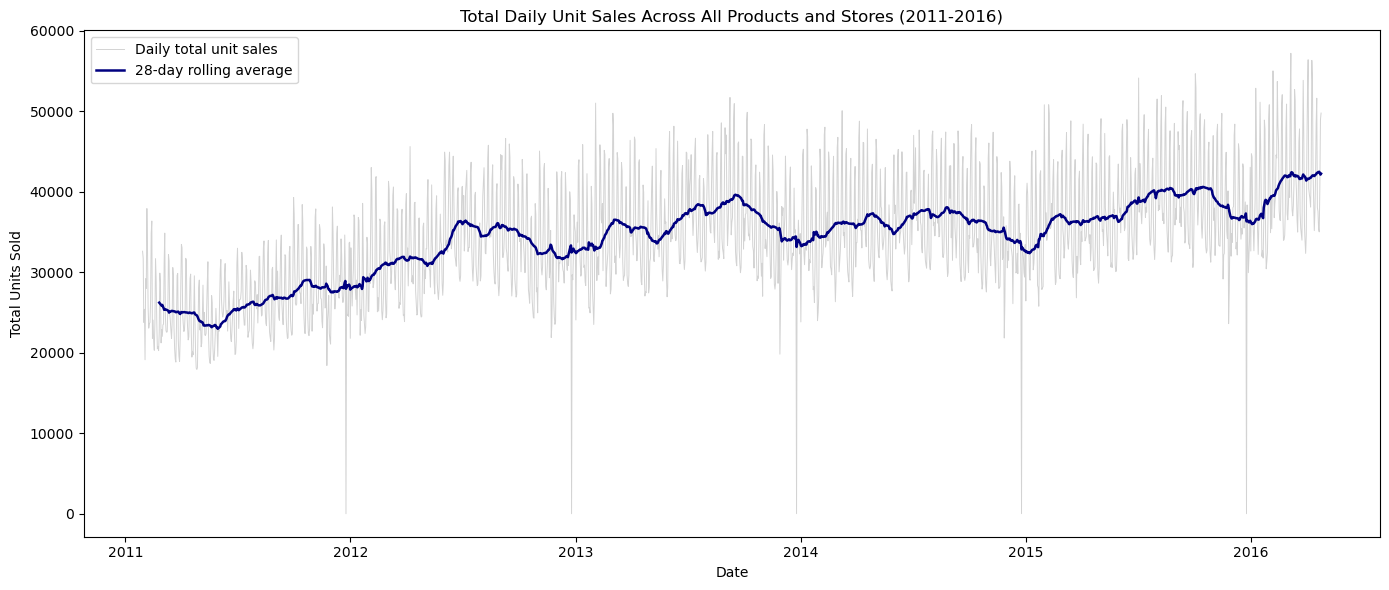

In [41]:
## Step 21: Visualize total daily unit sales across the entire dataset with a rolling average
import matplotlib.pyplot as plt

daily_totals = sales_long.groupby('date')['sales'].sum().reset_index().sort_values('date')
daily_totals['rolling_28'] = daily_totals['sales'].rolling(28).mean()

plt.figure(figsize=(14, 6))
plt.plot(daily_totals['date'], daily_totals['sales'], color='lightgray', linewidth=0.7, label='Daily total unit sales')
plt.plot(daily_totals['date'], daily_totals['rolling_28'], color='navy', linewidth=1.8, label='28-day rolling average')
plt.title('Total Daily Unit Sales Across All Products and Stores (2011-2016)')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.legend()
plt.tight_layout()
plt.savefig('timeline_total_sales.png', dpi=300)
plt.show()

           has_event  price_change  sell_price
category                                      
FOODS      -0.073458     -0.273295   -0.386576
HOBBIES    -0.064072      0.383736   -0.048906
HOUSEHOLD  -0.066391     -0.005944   -0.127573


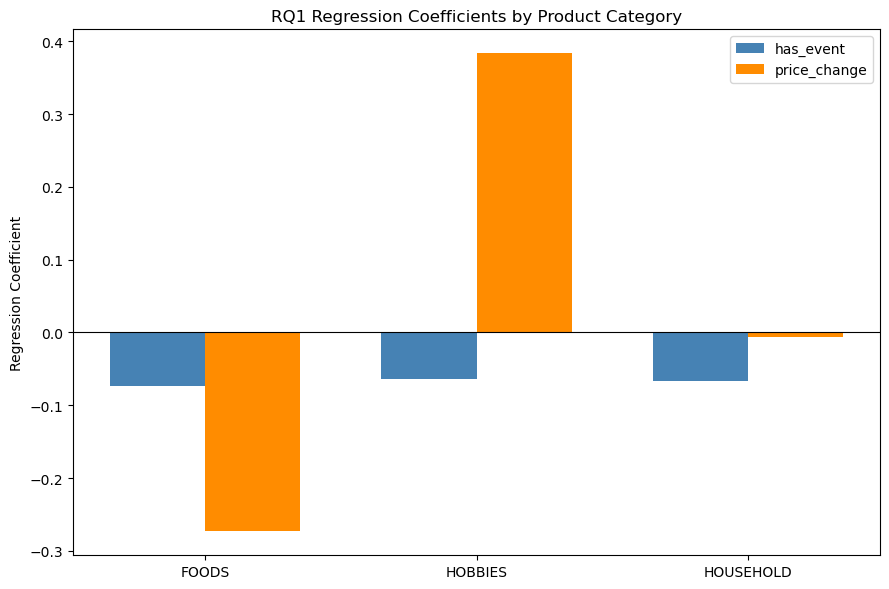

In [42]:
## Step 22: Visualize RQ1 regression coefficients by category (has_event and price_change)
import statsmodels.api as sm
import matplotlib.pyplot as plt

coef_records = []
for category in sales_long['cat_id'].unique():
    subset = sales_long[sales_long['cat_id'] == category]
    X_cat = subset[['has_event', 'price_change', 'sell_price']]
    X_cat = sm.add_constant(X_cat)
    y_cat = subset['sales']
    cat_model = sm.OLS(y_cat, X_cat).fit()
    coef_records.append({
        'category': category,
        'has_event': cat_model.params['has_event'],
        'price_change': cat_model.params['price_change'],
        'sell_price': cat_model.params['sell_price']
    })

coef_df = pd.DataFrame(coef_records).set_index('category')
print(coef_df)

# Plot has_event and price_change coefficients side by side, by category
fig, ax = plt.subplots(figsize=(9, 6))
x = np.arange(len(coef_df))
width = 0.35

ax.bar(x - width/2, coef_df['has_event'], width, label='has_event', color='steelblue')
ax.bar(x + width/2, coef_df['price_change'], width, label='price_change', color='darkorange')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(coef_df.index)
ax.set_ylabel('Regression Coefficient')
ax.set_title('RQ1 Regression Coefficients by Product Category')
ax.legend()
plt.tight_layout()
plt.savefig('rq1_coefficients_by_category.png', dpi=300)
plt.show()

                ETS  Baseline  Enhanced
Overall    0.822544  0.824554  0.824718
FOODS      0.872693  0.872929  0.869964
HOBBIES    0.761685  0.755186  0.758150
HOUSEHOLD  0.773490  0.785401  0.789390


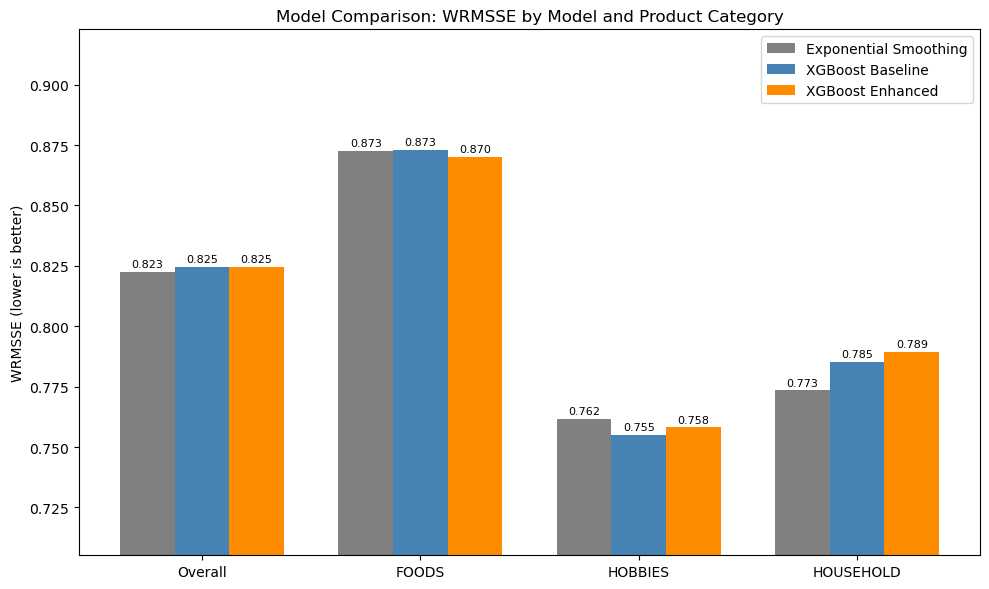

In [44]:
## Step 23: Compare WRMSSE across all three models, pooled and by category
categories_list = list(series_meta['cat_id'].unique())
group_labels = ['Overall'] + categories_list

wrmsse_table = {'ETS': [wrmsse_ets], 'Baseline': [wrmsse_baseline], 'Enhanced': [wrmsse_enhanced]}

for category in categories_list:
    cat_series = [sid for sid in valid_series if series_meta.loc[sid, 'cat_id'] == category]
    cat_weight_total = sum(weight_dict[sid] for sid in cat_series)

    for model_name, rmsse_dict in [
        ('ETS', rmsse_ets_dict),
        ('Baseline', rmsse_baseline_dict),
        ('Enhanced', rmsse_enhanced_dict)
    ]:
        cat_wrmsse = sum(weight_dict[sid] * rmsse_dict[sid] for sid in cat_series) / cat_weight_total
        wrmsse_table[model_name].append(cat_wrmsse)

wrmsse_df = pd.DataFrame(wrmsse_table, index=group_labels)
print(wrmsse_df)

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(group_labels))
width = 0.25

bars1 = ax.bar(x - width, wrmsse_df['ETS'], width, label='Exponential Smoothing', color='gray')
bars2 = ax.bar(x, wrmsse_df['Baseline'], width, label='XGBoost Baseline', color='steelblue')
bars3 = ax.bar(x + width, wrmsse_df['Enhanced'], width, label='XGBoost Enhanced', color='darkorange')

for bars in [bars1, bars2, bars3]:
    ax.bar_label(bars, fmt='%.3f', fontsize=8, padding=2)

ax.set_ylim(min(wrmsse_df.min()) - 0.05, max(wrmsse_df.max()) + 0.05)
ax.set_xticks(x)
ax.set_xticklabels(group_labels)
ax.set_ylabel('WRMSSE (lower is better)')
ax.set_title('Model Comparison: WRMSSE by Model and Product Category')
ax.legend()
plt.tight_layout()
plt.savefig('wrmsse_comparison.png', dpi=300)
plt.show()

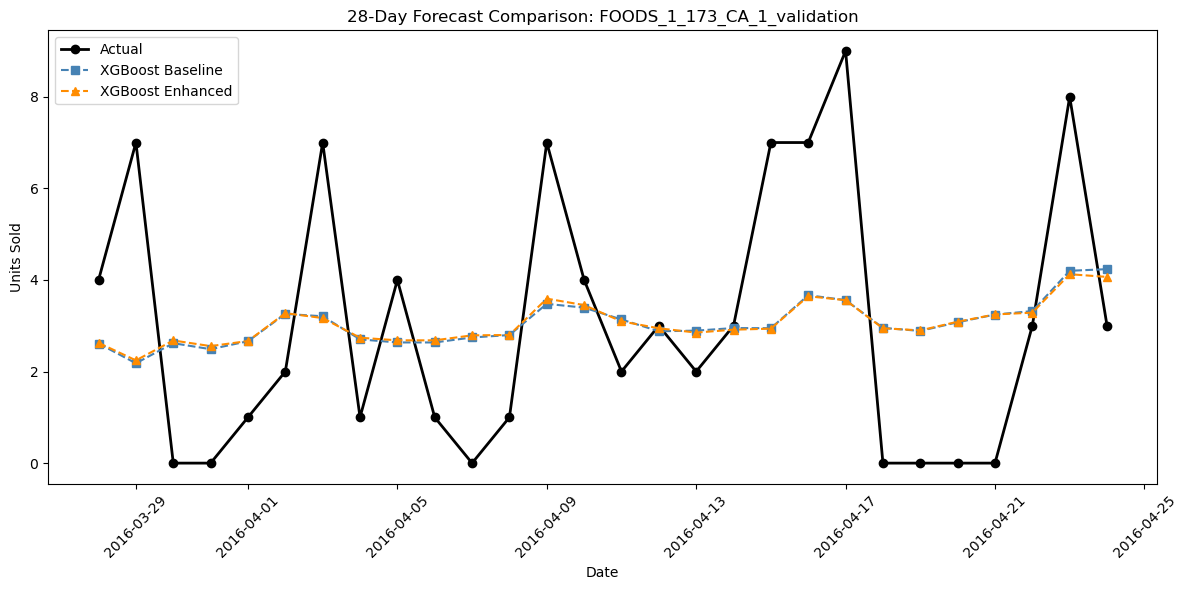

In [45]:
## Step 24: Visualize actual vs baseline vs enhanced forecasts for one example series
example_id = series_meta.index[0]  # same series used throughout this walkthrough

actual_vals = test_df.loc[test_df['id'] == example_id].sort_values('date')['sales'].values
dates = test_df.loc[test_df['id'] == example_id].sort_values('date')['date'].values

plt.figure(figsize=(12, 6))
plt.plot(dates, actual_vals, marker='o', label='Actual', color='black', linewidth=2)
plt.plot(dates, baseline_predictions[example_id], marker='s', label='XGBoost Baseline', color='steelblue', linestyle='--')
plt.plot(dates, enhanced_predictions[example_id], marker='^', label='XGBoost Enhanced', color='darkorange', linestyle='--')
plt.title(f'28-Day Forecast Comparison: {example_id}')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('example_series_forecast.png', dpi=300)
plt.show()

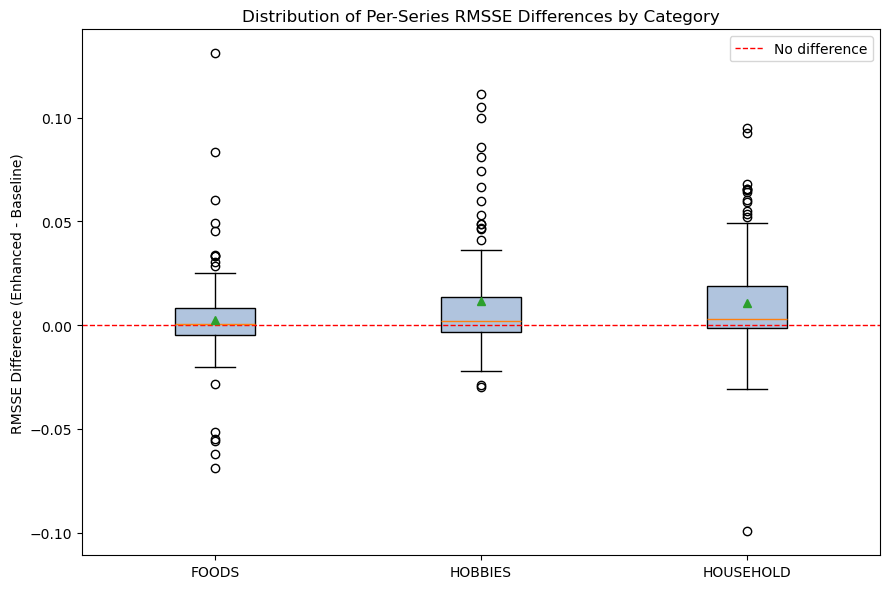

In [46]:
## Step 25: Visualize the distribution of per-series RMSSE differences by category
diff_records = []
for sid in valid_series:
    diff_records.append({
        'id': sid,
        'category': series_meta.loc[sid, 'cat_id'],
        'difference': rmsse_enhanced_dict[sid] - rmsse_baseline_dict[sid]
    })

diff_df = pd.DataFrame(diff_records)

fig, ax = plt.subplots(figsize=(9, 6))
categories_order = ['FOODS', 'HOBBIES', 'HOUSEHOLD']
data_by_cat = [diff_df.loc[diff_df['category'] == cat, 'difference'].values for cat in categories_order]

bp = ax.boxplot(data_by_cat, labels=categories_order, patch_artist=True, showmeans=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightsteelblue')

ax.axhline(0, color='red', linestyle='--', linewidth=1, label='No difference')
ax.set_ylabel('RMSSE Difference (Enhanced - Baseline)')
ax.set_title('Distribution of Per-Series RMSSE Differences by Category')
ax.legend()
plt.tight_layout()
plt.savefig('rmsse_difference_distribution.png', dpi=300)
plt.show()